In [71]:
import matplotlib.pyplot as plt
import pandas as pd
import json
import numpy as np
from matplotlib.lines import Line2D

Constants and helpful values:

In [72]:
# Kinarm visual rotations are CCW-positive, Hayashi's are CW-positive -> flip the sign.
# Kinarm proprioceptive perturbations are stored as an offset in cm from the straight path (10 cm reach). This maps the offset to degrees, already flipped.
prop_cm_to_deg = {
    -5.774: 30,
    -2.68: 15,
    0.0: 0,
    2.68: -15,
    5.774: -30,
}

prop_reversed =  {-30: 30,
    -15: 15,
    0.0: 0,
    15: -15,
    30: -30,
}
# Later used for easier indexing
vis_error_levels = [-45, -30, -15, 0, 15, 30, 45]
prop_error_levels = [-30, -15, 0, 15, 30]

# Colors as in Hayashi
# Lines coded by error size: Fig. 3A/B and Fig. 4A-E
error_colors = {
    -45: '#91278f',
    -30: '#2e3092',
    -15: '#00aeef',
    0: '#444444',
    15: '#f7931d',
    30: '#ed1c24', 
    45: '#ec008c',
}
# Fig. 3C / 3D
vis_line_color = '#ed1c24'  
prop_line_color = '#2e3092'  

# Fig. 4F-H has prop pert with a different palette than the other graphs
prop_error_colors = {
    -30: '#ed1c24',   # red
    -15: '#f7931d',   # orange
      0: '#00a14b',   # green
     15: '#91278f',   # purple
     30: '#2e3092',   # navy
}

# Parameters
SEC_TO_MS = 1000       # Force is sampled at 1000

# Time window in Fig 3 goes from -200 to 600 ms
WINDOW_PRE_MS = 200
WINDOW_POST_MS = 600
time_ms = np.arange(-WINDOW_PRE_MS, WINDOW_POST_MS)


Helper functions:

In [73]:
def json_decode(val):
    if isinstance(val, str):
        try:
            return json.loads(val)
        except (json.JSONDecodeError, TypeError):
            return val
    return val

def extract_force_window(force, onset_ms, pre_ms=WINDOW_PRE_MS, post_ms=WINDOW_POST_MS):
    """ Cut a window out of a force array that is around movement onset (which is the RT)

    Samples outside the recorded force stay NaN.
    Start and Stop is the sample position that I want. While First and Last is the real sample position I can take
    """
    force = np.array(force, dtype=float)
    start = onset_ms - pre_ms
    stop = onset_ms + post_ms
    first = max(start, 0)
    last = min(stop, len(force))

    window = np.full(pre_ms + post_ms, np.nan)
    window[first - start:last - start] = force[first:last]
    return window


def compute_aftereffect(force, onset_ms, peak_vel_ms):
    """ Integrate lateral force from force onset to the time of peak velocity 

    dx = 1 as we are computing everything in ms
    """
    force = np.array(force, dtype=float)
    start = max(onset_ms, 0)
    return np.trapezoid(force[start:peak_vel_ms + 1], dx=1) # + 1 so the force AT peak velocity is also included

def plot_force_profiles(ax, trials, group_col, levels, show_se):
    """
   Plot the mean lateral-force profile for each level of group_col on ax, which is the axes to draw
   """
    for level in levels:
        # window stores a list of Force Window that match the level of group_col
        windows = np.stack(trials.loc[trials[group_col] == level, 'Force Window'].to_list())
        # Get the mean and SE of windows while ignoring NaN values
        n_valid = np.sum(~np.isnan(windows), axis = 0)
        mean = np.nanmean(windows, axis = 0)
        se = np.nanstd(windows, axis = 0) / np.sqrt(n_valid)
        #Plot
        ax.plot(time_ms, mean, color=error_colors[level], lw=2, label=f'{level}°')
        if show_se:
            ax.errorbar(time_ms, mean, yerr=se, color=error_colors[level], alpha=0.2, lw=0.2)

    ax.axhline(0, color='lightgray', lw=0.8, zorder=0)
    ax.set_xlim(-WINDOW_PRE_MS, WINDOW_POST_MS)

def summarize_aftereffect(trials, group_col):
    """ Mean and standard error of the aftereffect for each level of group_col
    """
    grouped = trials.groupby(group_col)['Aftereffect']
    return pd.DataFrame({'mean': grouped.mean(), 'se': grouped.sem()})
    

Extracting data from csv:

In [89]:
# file_path = "/Users/ericjin/Git_Repository/hayashi/csv-files/P03.csv"
file_path = "/Users/ericjin/Git_Repository/hayashi/csv-files/P04.csv"
# file_path = "/Users/ericjin/Git_Repository/hayashi/csv-files/P02.csv"

In [90]:
# decodes all of the json strings in the csv file into arrays that are usable in python
df = pd.read_csv(file_path).map(json_decode)
# df = df.dropna()

**Step 1: Keep only the probe trials, and get the perturbation from the trial before.**

Trial types: 0 = perturbation trial, 1 = probe trial, 2 = null trial. Every set is (perturbation, probe, null, null), so the perturbation that caused the aftereffect measured in a probe trial is the one in the row directly above it.

In [91]:
# Creates a subset (df_clean) from df that includes only probe trials (trial type == 1) with their matched prop_per and vis_per from the corresponding perturbation trial as new columns
df_clean = df.copy()

df_clean["Matched Prop Pert"] = df_clean["Prop Pert"].shift(1)
df_clean["Matched Visual Pert"] = df_clean["Visual Pert"].shift(1)
prev_trial_type = df_clean["Trial Type"].shift(1)

df_clean = df_clean[df_clean["Trial Type"] == 1]
print(f"{len(df_clean)} probe trials")
# I want to implement a check that every probe trial is preceded by a perturbation trial
check = (prev_trial_type[df_clean.index] == 0).all()
if check == True:
    print("All probe trials preceded by pert trial")
else:
    print("Something is up...")

350 probe trials
All probe trials preceded by pert trial


**Step 2: Express the perturbations in Hayashi's convention (degrees).**

`Vis Error` / `Prop Error` are what all figures below are grouped by.

In [92]:
df_clean["Vis Error"] = -df_clean["Matched Visual Pert"].astype(int)
df_clean["Prop Error"] = df_clean["Matched Prop Pert"].round(3).map(prop_cm_to_deg)

# Should be 35 combinations x 10 repetitions
trials_per_condition = df_clean.groupby(["Vis Error", "Prop Error"]).size()
print(f"{len(trials_per_condition)} conditions, trials per condition: min {trials_per_condition.min()}, max {trials_per_condition.max()}")

7 conditions, trials per condition: min 10, max 10


**Step 3: Exclude trials without a usable reaction time.**

In [86]:
no_rt = df_clean["RTs"].isna().sum()
print(f"Removed {no_rt} probe trials without a RT")
df_clean = df_clean[df_clean["RTs"].notna()].reset_index(drop=True)

Removed 1 probe trials without a RT


**Step 4: Align the force profiles to movement onset, and compute the aftereffect of every probe trial.**

- `Force Window`: lateral force from -200 to +600 ms around movement onset (RT), NaN where no data exists
- `Aftereffect`: lateral force integrated from force onset to the time of peak velocity, in N·ms (Hayashi: "force impulse").

In [87]:
# Adds 2 new columns to df_clean
df_clean["Onset (ms)"] = (df_clean["RTs"] * SEC_TO_MS).round().astype(int)
df_clean["Peak Vel Time (ms)"] = (df_clean["Time PV"] * SEC_TO_MS).round().astype(int)

# Adds a new column of "Force Window" to df_clean
force_window = []
for force, onset in zip(df_clean["Force X"], df_clean["Onset (ms)"]):
    force_window.append (extract_force_window(force, onset))
df_clean["Force Window"] = force_window
# Adds a new column of "Aftereffect" to df_clean
aftereffect = []
for force, onset, peak_vel in zip(df_clean["Force X"], df_clean["Onset (ms)"], df_clean["Peak Vel Time (ms)"]):
    aftereffect.append(compute_aftereffect(force, onset, peak_vel))
df_clean["Aftereffect"] = aftereffect


**Figure 3A:** Lateral force in the probe trial after a **visual-only** perturbation. Only trials where the proprioceptive error was 0° are used

<font color = "red"> *NOTE:* The SE right now is just for one participant, but the paper is for between participants </font>

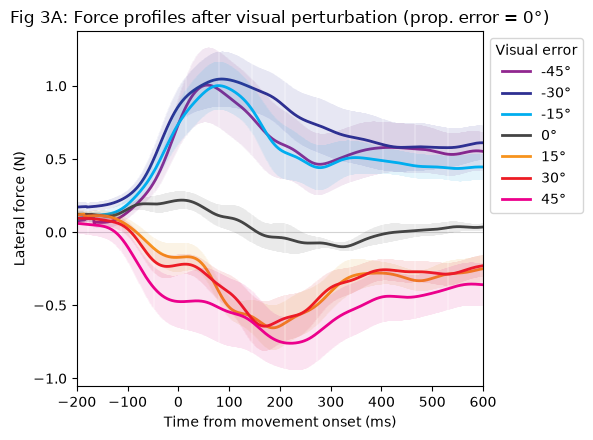

In [88]:
visual_only = df_clean[df_clean["Prop Error"] == 0]

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_force_profiles(ax, visual_only, "Vis Error", vis_error_levels, show_se=True)

ax.set_xlabel("Time from movement onset (ms)")
ax.set_ylabel("Lateral force (N)")
ax.set_title("Fig 3A: Force profiles after visual perturbation (prop. error = 0°)")
ax.legend(title="Visual error", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [69]:
# import seaborn as sns

# fig, ax = plt.subplots()
# sns.lineplot(data=visual_only, x=time_ms, y="Force Window", hue="Vis Error", ax=ax)
# plt.show()

**Figure 3B:** Lateral force in the probe trial after a **proprioceptive-only** perturbation. Only trials where the visual error was 0° are used 

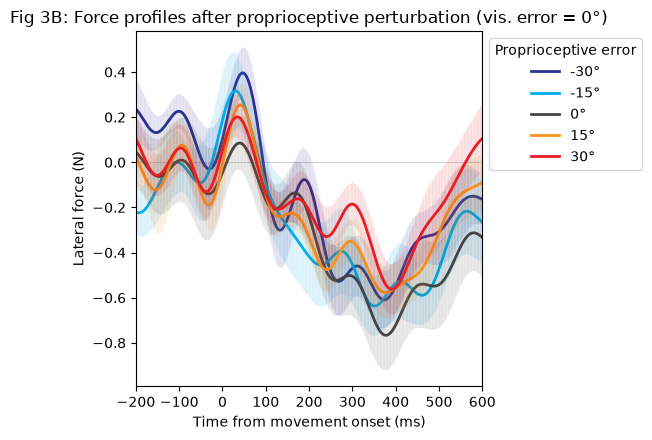

In [70]:
proprioceptive_only = df_clean[df_clean["Vis Error"] == 0]

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_force_profiles(ax, proprioceptive_only, "Prop Error", prop_error_levels, show_se=True)

ax.set_xlabel("Time from movement onset (ms)")
ax.set_ylabel("Lateral force (N)")
ax.set_title("Fig 3B: Force profiles after proprioceptive perturbation (vis. error = 0°)")
ax.legend(title="Proprioceptive error", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

**Figure 3C:** Aftereffect as a function of visual error (proprioceptive error = 0°).

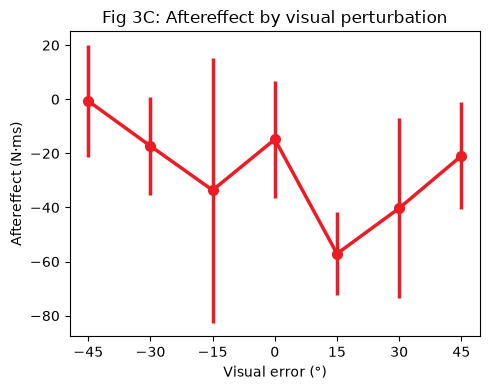

In [21]:
aftereffect_summary = summarize_aftereffect(visual_only, "Vis Error")

fig, ax = plt.subplots(figsize=(5, 4))
ax.errorbar(vis_error_levels,
aftereffect_summary["mean"], 
yerr=aftereffect_summary["se"], 
fmt="o-", 
color=vis_line_color, 
lw=2.5, ms=7, capsize=0)

ax.set_xticks(vis_error_levels)
ax.set_xlabel("Visual error (°)")
ax.set_ylabel("Aftereffect (N·ms)")
ax.set_title("Fig 3C: Aftereffect by visual perturbation")
plt.tight_layout()
plt.show()

**Figure 3D:** Aftereffect as a function of proprioceptive error (visual error = 0°).

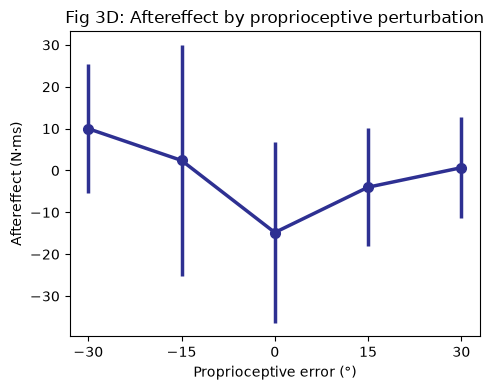

In [22]:
aftereffect_summary = summarize_aftereffect(proprioceptive_only, "Prop Error")

fig, ax = plt.subplots(figsize=(5, 4))
ax.errorbar(prop_error_levels,
aftereffect_summary["mean"], 
yerr=aftereffect_summary["se"], 
fmt="o-", 
color=prop_line_color, 
lw=2.5, ms=7, capsize=0)

ax.set_xticks(prop_error_levels)
ax.set_xlabel("Proprioceptive error (°)")
ax.set_ylabel("Aftereffect (N·ms)")
ax.set_title("Fig 3D: Aftereffect by proprioceptive perturbation")
plt.tight_layout()
plt.show()

**Figure 4A-E:** force profile for each visual error, one panel per proprioceptive error (+30° in panel A down to -30° in panel E, as in the paper).

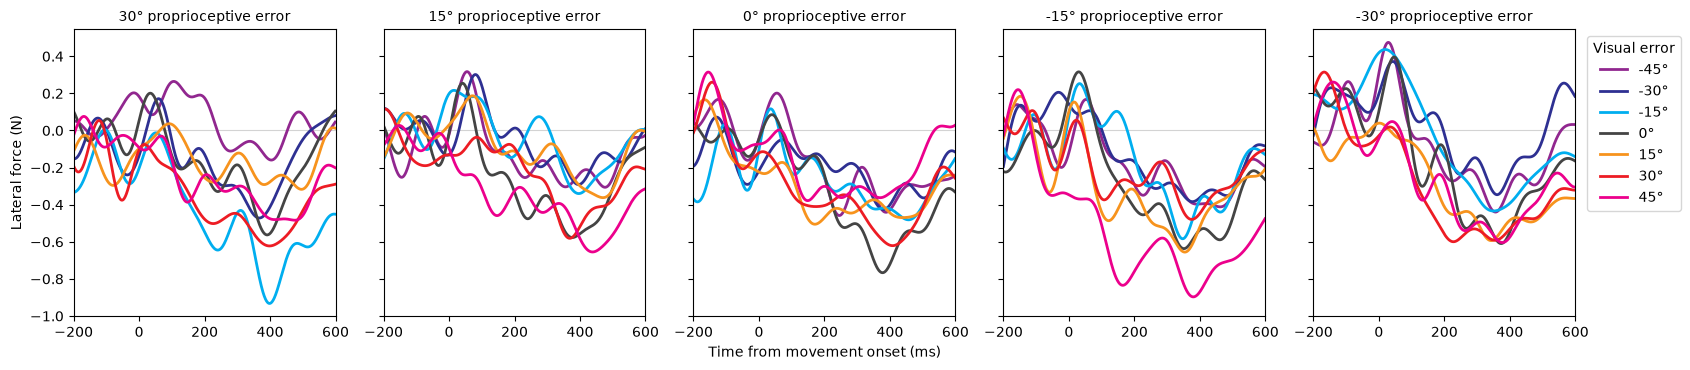

In [23]:
fig, axes = plt.subplots(1, len(prop_error_levels), figsize=(17, 3.8), sharey=True)
# Figures 4A-E run from +30 to -30. Iterative through each subplot. I use reversed() so it matches the order of Hayashi's graphs
for ax, prop_error in zip(axes, reversed(prop_error_levels)):
    same_prop = df_clean[df_clean["Prop Error"] == prop_error]
    plot_force_profiles(ax, same_prop, "Vis Error", vis_error_levels, show_se=False) # can add show_se=True to see SE

    ax.set_xlim(-WINDOW_PRE_MS, WINDOW_POST_MS)
    ax.set_title(f"{prop_error}° proprioceptive error", fontsize=10)
axes[0].set_ylabel("Lateral force (N)")
axes[2].set_xlabel("Time from movement onset (ms)")
axes[-1].legend(title="Visual error", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


**Figure 4F:** Aftereffect vs. visual error, each line shows the proprioceptive error. Colors code the *proprioceptive* error.

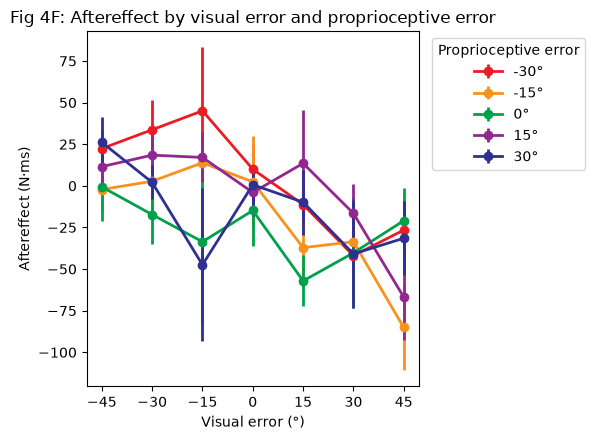

In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))

for prop_error in prop_error_levels:
    aftereffect_summary = summarize_aftereffect(df_clean[df_clean["Prop Error"] == prop_error], "Vis Error")
    ax.errorbar(vis_error_levels, aftereffect_summary["mean"], yerr=aftereffect_summary["se"], fmt="o-", 
    color=prop_error_colors[prop_error],
    lw=2, ms=6, label=f"{prop_error}°")

ax.set_xticks(vis_error_levels)
ax.set_xlabel("Visual error (°)")
ax.set_ylabel("Aftereffect (N·ms)")
ax.set_title("Fig 4F: Aftereffect by visual error and proprioceptive error")
ax.legend(title="Proprioceptive error", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


**Figure 4G:** Amplitude modulation = mean aftereffect for the three negative visual pert − mean aftereffect for the three positive visual pert

Error bars: the amplitude is a combination of 6 independent cell means (3 negative + 3 positive visual levels), so its SE is computed from the SEs of those 6 cells.

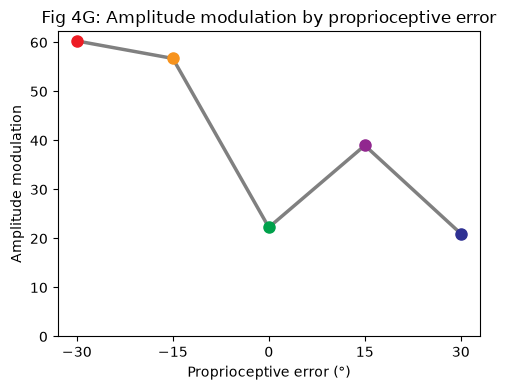

In [25]:
# I first compute amplitude modulation. Group by trials of one prop pert.
rows = {}
for prop_error, same_prop in df_clean.groupby("Prop Error"):
    # Within that one type of prop pert, I group by Visual pert. Separate into Positive and Negative Vis Error then get the aftereffect mean for each Vis Error
     unit = same_prop.groupby("Vis Error")['Aftereffect'].agg(['mean', 'sem'])
     negative = unit[unit.index < 0]
     positive = unit[unit.index > 0]

     neg_mean = negative['mean'].mean()
     pos_mean = positive['mean'].mean()
     amplitude = neg_mean - pos_mean

     rows[prop_error] = {'mean': amplitude}

amplitude_modulation = pd.DataFrame(rows).T

#Plot
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(amplitude_modulation.index, amplitude_modulation["mean"], color="gray", 
lw=2.5, 
zorder=0)
for prop_error, row in amplitude_modulation.iterrows():
    ax.errorbar(prop_error, row["mean"], 
    fmt="o", 
    color=prop_error_colors[prop_error],
    ecolor="gray", lw=2, ms=8, capsize=0)

ax.set_xticks(prop_error_levels)
ax.set_xlabel("Proprioceptive error (°)")
ax.set_ylabel("Amplitude modulation")
ax.set_ylim(bottom=0)
ax.set_title("Fig 4G: Amplitude modulation by proprioceptive error")
plt.tight_layout()
plt.show()

**Figure 4H:** Aftereffect when the visual and proprioceptive errors are identical

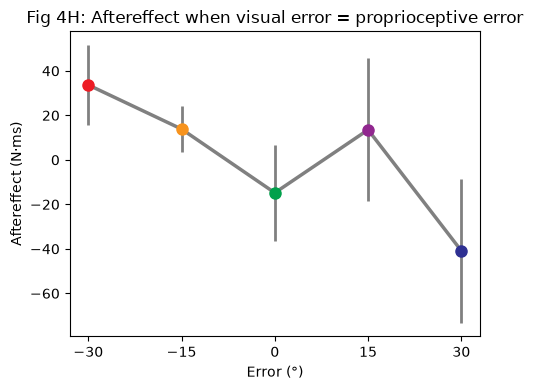

In [26]:
# Game plan:
# 1. make df where df_clean["Vis Error"] == df_clean["Prop Error"]
# 2. Use summarize_aftereffect on new df, grouped either "Prop Error" or "Vis Error" as both are same
# 3. Iterate through that df to plot each datapoint with mean and SE
df_equal = df_clean[df_clean["Vis Error"] == df_clean["Prop Error"]]
aftereffect_summary = summarize_aftereffect(df_equal, "Prop Error")

fig, ax = plt.subplots(figsize=(5,4))
ax.plot(aftereffect_summary.index, aftereffect_summary["mean"], color = "gray", lw = 2.5)
for error, row in aftereffect_summary.iterrows():
    ax.errorbar(error, row["mean"],yerr = row["se"], fmt = "o", color =prop_error_colors[error], ecolor = "gray", lw = 2, ms = 8 )

ax.set_xticks(prop_error_levels)
ax.set_xlabel("Error (°)")
ax.set_ylabel("Aftereffect (N·ms)")
ax.set_title("Fig 4H: Aftereffect when visual error = proprioceptive error")
plt.tight_layout()
plt.show()

In [106]:

theta = 30 * (np.pi/180)
dis = np.tan(theta)
dis * 10 # This is the distance used for prop_pert
10 * 0.01

# np.arctan(dis) * (180/np.pi) # Uncomment this to check
# So I think it's a rounding error last time we checked

0.1

- prop_pert = number used to modify the x position of the Prop Target
- x2 = x position in m (after applying prop_pert) of the Prop Target
- distToLine = always tracks the hand position relative to the Home-Target straight line
- Calculates slope between x1 (Home) and x2 (Prop Target) and then gets the perpendicular slope perpM
